# PerfuSense AI · Lesson 2: a second dataset, the empty bed, and combining mats

In Lesson 1 we trained on 13 people on one mat. This lesson adds **PoPu-Data**: 60 more people on a different mat. The new skills are about **collecting datasets together**:

1. Reading a new file format and joining its files into 30-frame recordings.
2. Finding out that one dataset is **mirrored**, which would silently swap left and right.
3. Handling the **empty bed**.
4. Putting two different mats into one common format.
5. Measuring how badly a model trained on one mat works on another, and how combining helps.

> Research prototype, not a medical device. Nothing here is a clinical claim.

**Why do we train again?** The model's *design* stays the same as Lesson 1. Only its *weights* change, because the data changes. A model cannot learn from new people without training on them. Each run takes minutes.

**New: shared code.** The cleaning and scaling must be identical in every lesson and on the server, so they now live in one package: `ai/perfusense_ai/data.py` and `model.py`. To keep every step visible, the `show()` helper below prints the real code of each function right where we use it.

In [1]:
import sys
import inspect
import json
import time

sys.path.insert(0, "..")   # lets the notebook import ai/perfusense_ai

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from perfusense_ai import data as D
from perfusense_ai import model as M


def show(*functions):
    """Print the real source code of our shared functions."""
    for f in functions:
        print(inspect.getsource(f))

print("data folder:", D.data_root())

data folder: D:\Projects\Perfusense\datasets


## Step 1 · Open one PoPu file

PoPu is stored as JSON, not as a text table. One file holds one short recording from the **Tactilus** sheet that lies on top of the mattress.

In [2]:
path = D.popu_dir() / "1" / "supine1_0.json"
with open(path) as f:
    d = json.load(f)

print({k: v for k, v in d.items() if k != "snapshots"})
first = d["snapshots"]["0"]
print("snapshots in this file:", len(d["snapshots"]))
print("one snapshot:", {k: (f"list of {len(v)} numbers" if isinstance(v, list) else v) for k, v in first.items()})

{'volunteer_id': '1', 'sex': 'female', 'height': 157, 'weight': 73, 'tactilus_columns': 27, 'tactilus_rows': 64, 'position': 'supine', 'variation': '1'}
snapshots in this file: 10
one snapshot: {'id': '290511164218', 'tactilus_readings': 'list of 1728 numbers'}


Each snapshot is 1,728 numbers = 64 rows × 27 columns, and every person has 86 files:

| Files | What | Count per person |
|---|---|---|
| `supine1_0` … `right7_2` | 4 postures × 7 variations × 3 small shifts | 84 |
| `empty1` | the empty bed | 1 |
| `others` | every frame **between** the labelled positions | 1 |

Keep `others` in mind. It becomes very important in Lesson 4.

## Step 2 · The problem: only 10 snapshots per file

Our model needs 30 frames. One file has 10. But the README says the person "slightly shifts" twice per pose, so `_0`, `_1`, `_2` are the same pose. Three files × 10 snapshots = **30 snapshots**. Exactly one window.

How much time do those 30 snapshots cover? The README does not say. But the `id` looks like a clock: `290511164218` reads as day 29, month 05, 11 h, 16 min, 42.18 s. If that is right, the differences should look regular.

In [3]:
show(D.popu_time)

parts = [D.load_popu_file(D.popu_dir() / "1" / f"supine1_{k}.json")[1] for k in range(3)]
times = np.concatenate(parts)
gaps = np.diff(times)
print("seconds between snapshots:", np.round(gaps, 2))
print(f"typical gap {np.median(gaps):.2f} s; all 30 snapshots cover {times[-1] - times[0]:.0f} s")

def popu_time(snapshot_id):
    """A PoPu snapshot id is a clock reading DDMMHHMMSScc. Returns seconds."""
    s = str(snapshot_id).zfill(12)
    day, _, hour, minute, sec, centi = (int(s[i:i + 2]) for i in range(0, 12, 2))
    return ((day * 24 + hour) * 60 + minute) * 60 + sec + centi / 100

seconds between snapshots: [ 0.56  0.57  0.56  0.57  0.58  0.57  0.57  0.58  0.5  12.67  0.51  0.54
  0.51  0.5   0.52  0.53  0.52  0.53  0.52  4.4   0.52  2.07  0.52  0.51
  0.52  0.5   0.52  0.51  0.52]
typical gap 0.52 s; all 30 snapshots cover 33 s


So the clock idea works: snapshots come about every **0.5 s**, in short bursts, with longer gaps (up to 13 s here) where the person shifts. The 30 snapshots cover about **33 seconds**, very close to our 30-second window. It is not a perfect 1-frame-per-second stream, but it fits well. (I worked this timing out from the ids. I could not read the paper to confirm it.)

Here is the code that joins the files, and the loader for PmatData with the Lesson 1 cleaning built in:

In [4]:
show(D.load_popu_file, D.load_popu, D.load_pmd, D.drop_bad_frames)

def load_popu_file(path, mirror=True):
    """One PoPu JSON file -> frames (n, 64, 27), times (n,) in seconds.

    mirror=True flips the columns into the canonical view: Lesson 2 shows PoPu needs this.
    """
    with open(path) as f:
        snapshots = json.load(f)["snapshots"].values()
    frames = np.array([s["tactilus_readings"] for s in snapshots], dtype="float32").reshape(-1, 64, 27)
    times = np.array([popu_time(s["id"]) for s in snapshots])
    return (frames[:, :, ::-1] if mirror else frames), times

def load_popu(mirror=True):
    """Each position's three 10-snapshot files joined into one 30-snapshot recording. Prone is kept."""
    root = popu_dir()
    recordings = []
    for person in range(1, 61):
        for label in ("supine", "prone", "left", "right"):
            for variation in range(1, 8):
                parts = [load_popu_file(root / str(person) / f"{label}{variation}_{k}.json", mirror)[0]
                         for k in range(3)]
                recording

In [5]:
t0 = time.time()
pmd = D.load_pmd()
popu_raw = D.load_popu(mirror=False)          # exactly as stored in the files
print(f"loaded in {time.time() - t0:.0f} s: PmatData {len(pmd)} recordings, PoPu {len(popu_raw)} recordings")
print(pd.Series([r["label"] for r in popu_raw]).value_counts().to_dict())

loaded in 30 s: PmatData 221 recordings, PoPu 1680 recordings
{'supine': 420, 'prone': 420, 'left': 420, 'right': 420}


**Decision: drop prone for now.** PoPu has a fourth posture, prone (face down). PmatData does not, and our classes are supine / left / right. So we use 3 × 420 = 1,260 PoPu recordings. In Lesson 4 prone comes back, because we need the whole session.

## Step 3 · Look before combining: the mirror problem

Two datasets can use the same word and mean opposite things. Draw the average map of each class on each mat:

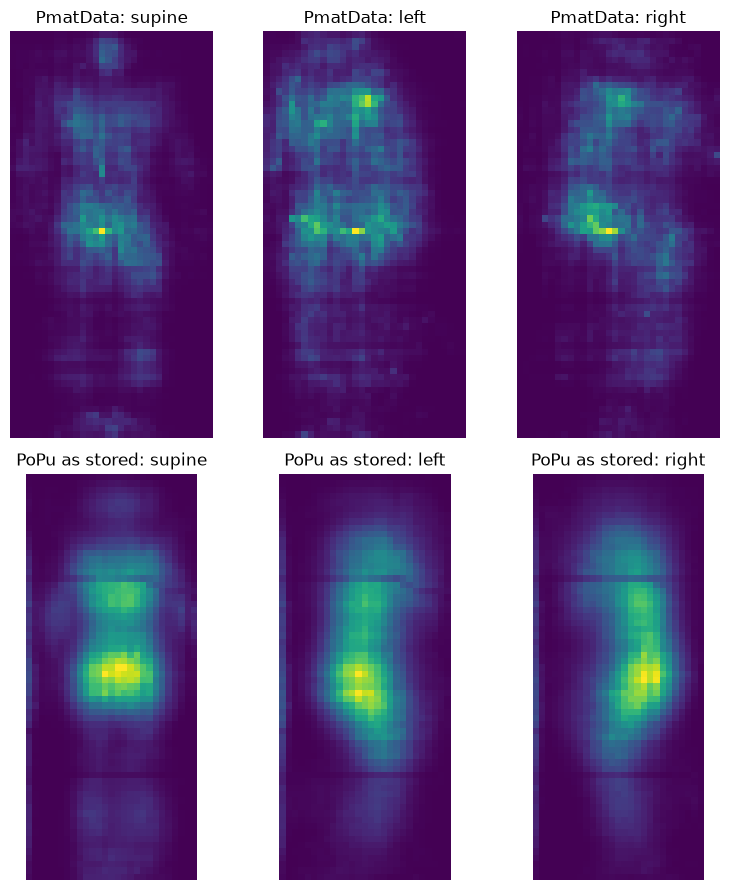

In [6]:
def class_map(recordings, label):
    return np.mean([r["frames"].mean(axis=0) for r in recordings if r["label"] == label], axis=0)

fig, axes = plt.subplots(2, 3, figsize=(8, 9))
for row, (name, recs) in enumerate([("PmatData", pmd), ("PoPu as stored", popu_raw)]):
    for col, label in enumerate(D.CLASSES):
        axes[row, col].imshow(class_map(recs, label))
        axes[row, col].set_title(f"{name}: {label}")
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()

Look at the **side postures** and find the hips, the brightest area. In PoPu "right", the hips sit on the **right** of the picture. In PmatData "right", they sit on the **left** of the picture. The same word, opposite pictures.

So one of the two is seen from the opposite side, like a picture in a mirror. If we simply mix them, the model is told that the same shape is both "left" and "right". For PerfuSense that is the worst possible mistake.

Seeing it is a hint. Let's **measure** it: train a simple model on one mat, test it on the other, with and without flipping PoPu's columns. If the flip is right, accuracy jumps. (Guessing = 33 %.)

Everything first goes into the same size. PoPu is narrower (27 columns against 32), so we add empty columns instead of stretching it. That keeps the body at the same real size.

In [7]:
show(D.pad_to_width, D.area_resize, D.normalise_window, D.whole_bed_view, D.windows_from_recordings)

def pad_to_width(frames, width=32):
    """Add empty columns on both sides, so a narrower mat keeps its real scale."""
    missing = width - frames.shape[2]
    left = missing // 2
    return np.pad(frames, ((0, 0), (0, 0), (left, missing - left)))

def area_resize(frames, h=GRID, w=GRID):
    """(T, H, W) -> (T, h, w) by averaging areas. Every sensor counts, even when sizes do not divide."""
    frames = np.asarray(frames, dtype="float32")
    _, H, W = frames.shape

    def weights(n_in, n_out):
        m = np.zeros((n_out, n_in), dtype="float32")
        edges = np.linspace(0, n_in, n_out + 1)
        for i in range(n_out):
            for j in range(n_in):
                m[i, j] = max(0.0, min(edges[i + 1], j + 1) - max(edges[i], j))
        return m / m.sum(axis=1, keepdims=True)

    return np.einsum("ih,thw,jw->tij", weights(H, h), frames, weights(W, w))

def normalise_window(x, eps=1e-6):
    """Scale a window to 0..1 by its own 99th percentile. Used in training AND serving.""

In [8]:
Xp, yp, gp = D.windows_from_recordings(pmd, D.whole_bed_view)
Xq, yq, gq = D.windows_from_recordings(popu_raw, D.whole_bed_view)
print("PmatData windows:", Xp.shape, "| PoPu windows:", Xq.shape)

def flat(X):
    """Average over time: one 100-number picture per window."""
    return X.mean(axis=1).reshape(len(X), -1)

def linear(X, y):
    return LogisticRegression(max_iter=3000, class_weight="balanced").fit(flat(X), y)

mirrored = Xq[..., ::-1]
print("train PmatData -> test PoPu as stored:", M.score(yq, linear(Xp, yp).predict(flat(Xq))))
print("train PmatData -> test PoPu mirrored: ", M.score(yq, linear(Xp, yp).predict(flat(mirrored))))
print("train PoPu as stored -> test PmatData:", M.score(yp, linear(Xq, yq).predict(flat(Xp))))
print("train PoPu mirrored  -> test PmatData:", M.score(yp, linear(mirrored, yq).predict(flat(Xp))))

PmatData windows: (1409, 30, 10, 10) | PoPu windows: (1260, 30, 10, 10)
train PmatData -> test PoPu as stored: {'balanced_acc': 0.351, 'macro_f1': 0.263}
train PmatData -> test PoPu mirrored:  {'balanced_acc': 0.586, 'macro_f1': 0.572}
train PoPu as stored -> test PmatData: {'balanced_acc': 0.35, 'macro_f1': 0.335}
train PoPu mirrored  -> test PmatData: {'balanced_acc': 0.735, 'macro_f1': 0.745}


Without the flip, the scores sit at guessing level (35 %). With the flip they jump to 59 % and 74 %. So **PoPu must be mirrored** to match PmatData.

**Decision: one common picture format for every dataset, called the canonical view:**

- row 0 is the head end;
- column 0 is on the patient's **left**, the same as `server/lib/zones.ts` (`col < mid` = LEFT).

`load_popu()` now mirrors by default. The same check must be done on our own mat: lie on your left side and confirm the model says left. If the mat's cable is on the other side, the columns must be flipped once, at the start.

## Step 4 · The empty bed

Should "empty" be a fourth class, or a simple rule? Look at the numbers first.

empty frames: 600 | frames with a person: 37800
total pressure, empty : median 37, largest 1965
total pressure, person: median 10834, smallest 3416
hottest cell, empty : largest 104.0
hottest cell, person: smallest 29.0


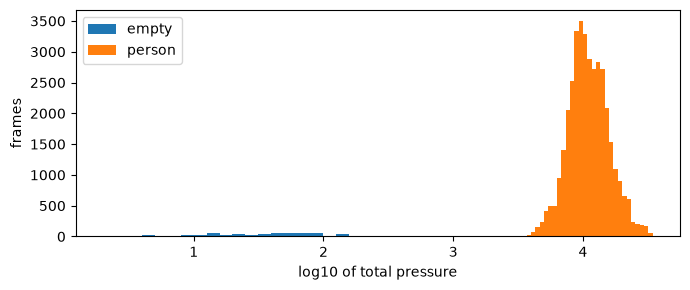

In [9]:
popu = [{**r, "frames": r["frames"][:, :, ::-1]} for r in popu_raw if r["label"] != "prone"]
del popu_raw

empty = np.concatenate([D.load_popu_file(D.popu_dir() / str(p) / "empty1.json")[0] for p in range(1, 61)])
person = np.concatenate([r["frames"] for r in popu])

print("empty frames:", len(empty), "| frames with a person:", len(person))
print(f"total pressure, empty : median {np.median(empty.sum((1, 2))):.0f}, largest {empty.sum((1, 2)).max():.0f}")
print(f"total pressure, person: median {np.median(person.sum((1, 2))):.0f}, smallest {person.sum((1, 2)).min():.0f}")
print(f"hottest cell, empty : largest {empty.max()}")
print(f"hottest cell, person: smallest {person.max(axis=(1, 2)).min()}")

plt.figure(figsize=(7, 3))
plt.hist(np.log10(empty.sum((1, 2)) + 1), bins=30, label="empty")
plt.hist(np.log10(person.sum((1, 2)) + 1), bins=30, label="person")
plt.xlabel("log10 of total pressure"); plt.ylabel("frames"); plt.legend(); plt.tight_layout(); plt.show()

Look carefully at the two measures:

- **Total pressure separates them cleanly.** The largest empty total is 1,965, the smallest with a person is 3,416, and the typical person is about 300 times the typical empty bed.
- **The hottest cell does not.** One empty frame has a cell at 104, the top of the scale, while some frames with a person peak at only 29.

The old plan said "empty = no cell above a small threshold". This data shows that one stray cell would break that rule. **So the rule must use total or average pressure, not the hottest cell.**

| Option | For | Against |
|---|---|---|
| "empty" as a 4th class | one model does everything | only 600 empty frames; and per-window scaling would blow up the noise on an empty mat into a fake picture |
| **a rule that runs first** | clear, testable, cannot be fooled by scaling | needs a threshold measured on each mat |

**Decision: a rule, before the model.** The service still answers with four results (supine, left, right, empty). The model itself keeps three classes. The dataset plan called "empty" a fourth class, and the service output matches that. Only the way we reach it differs. The real threshold must be measured on our own mat. We come back to this in Lesson 3, because a small mat can look empty even with a person in the bed.

## Step 5 · How far does one mat travel?

Now the real question: train the Lesson 1 models on one mat and test them on the other, whose people and sensor they never saw.

In [10]:
del person
Xq, yq, gq = D.windows_from_recordings(popu, D.whole_bed_view)

def one_way(builder, X, y, people, X_test, y_test):
    """Train on one dataset (some of its people for validation), test on the other dataset."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    names = np.unique(people)
    va = np.isin(people, names[: max(2, len(names) // 8)])
    m = builder()
    M.train(m, X[~va], y[~va], X[va], y[va])
    return M.score(y_test, M.predict(m, X_test))["balanced_acc"]

rows = []
for name, builder in [("baseline", M.build_baseline), ("transformer", M.build_transformer)]:
    rows.append({"model": name,
                 "PmatData -> PoPu": one_way(builder, Xp, yp, gp, Xq, yq),
                 "PoPu -> PmatData": one_way(builder, Xq, yq, gq, Xp, yp)})
pd.DataFrame(rows)

,model,PmatData -> PoPu,PoPu -> PmatData
0,baseline,0.530,0.756
1,transformer,0.552,0.722


This is the most important table of the lesson. In Lesson 1 the score on *new people on the same mat* was about 96 %. On a **new mat** it falls a lot, even with the whole bed visible.

It also shows a direction: the model trained on PoPu's 60 people travels better (about 75 %) than the model trained on PmatData's 13 (about 54 %). More people probably help, but the mats differ too, so this table alone cannot prove why. "Your turn" exercise 1 tests it.

Our Velostat mat is a new mat too, so expect the same kind of drop. That is why the plan ends by adapting on our own recordings, and why a public score is not our mat's score.

## Step 6 · Combine the datasets

Now put both together and test by person. There are 73 people, so instead of 73 trainings we use **5-fold by person**: split the people into 5 groups, train on 4, test on the 5th, rotate. Every person is tested once by a model that never saw them.

Each person's name carries the dataset (`pmd-3`, `popu-17`), so two different "person 3"s never get mixed up.

In [11]:
show(M.cross_validate)

def cross_validate(builder, X, y, people, folds=5, batch_size=64, **train_args):
    """Train `folds` models. Every person is predicted once, by a model that never saw them."""
    pred = np.zeros_like(y)
    for k, (tr, te) in enumerate(GroupKFold(folds).split(X, y, people)):
        train_people = np.unique(people[tr])
        val_people = np.random.default_rng(k).choice(train_people, max(2, len(train_people) // 8), replace=False)
        va = np.isin(people[tr], val_people)
        keras.backend.clear_session()       # forget old models: keeps memory and speed steady
        keras.utils.set_random_seed(42)
        m = builder()
        train(m, X[tr][~va], y[tr][~va], X[tr][va], y[tr][va], batch_size=batch_size, **train_args)
        pred[te] = predict(m, X[te])
    return pred



In [12]:
X = np.concatenate([Xp, Xq]); y = np.concatenate([yp, yq]); people = np.concatenate([gp, gq])
source = np.array([p.split("-")[0] for p in people])
print("combined windows:", X.shape, "| people:", len(set(people)), "| per class:", dict(zip(D.CLASSES, np.bincount(y))))

predictions, rows = {}, []
for name, builder in [("baseline", M.build_baseline), ("transformer", M.build_transformer)]:
    t0 = time.time()
    pred = M.cross_validate(builder, X, y, people)
    predictions[name] = pred
    rows.append({"model": name, "all": M.score(y, pred)["balanced_acc"],
                 "PmatData people": M.score(y[source == "pmd"], pred[source == "pmd"])["balanced_acc"],
                 "PoPu people": M.score(y[source == "popu"], pred[source == "popu"])["balanced_acc"],
                 "macro F1": M.score(y, pred)["macro_f1"], "seconds": round(time.time() - t0)})
pd.DataFrame(rows)

combined windows: (2669, 30, 10, 10) | people: 73 | per class: {'supine': np.int64(1166), 'left': np.int64(756), 'right': np.int64(747)}


,model,all,PmatData people,PoPu people,macro F1,seconds
0,baseline,0.956,0.945,0.961,0.957,45
1,transformer,0.965,0.955,0.970,0.967,165


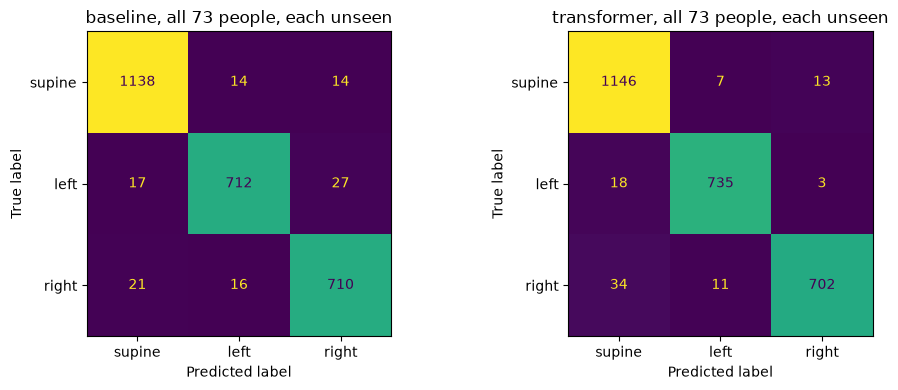

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=D.CLASSES).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name}, all 73 people, each unseen")
plt.tight_layout(); plt.show()

## What we learned

| Test (balanced accuracy) | Baseline | Transformer |
|---|---|---|
| New mat: trained on PmatData, tested on PoPu | 53.0 % | 55.2 % |
| New mat: trained on PoPu, tested on PmatData | 75.6 % | 72.2 % |
| Combined, 73 unseen people (5-fold by person) | 95.6 % | 96.5 % |
| — PmatData people | 94.5 % | 95.5 % |
| — PoPu people | 96.1 % | 97.0 % |

- **Combining works.** A model that has seen both mats reaches about 96 % on new people from both, while a model that saw one mat falls to 53–76 % on the other.
- **Check meaning, not just shape.** Both datasets said "left", and they were mirror images. Without the flip the score was 35 %, which is guessing.
- **Empty is a rule on total pressure, not a class.**
- **The Transformer is still about level with the baseline.** It is about one point higher here. It did swap left and right less: 14 of 1,503 side windows (0.9 %) against 43 (2.9 %). That is one run with one set of folds, so it is a hint, not a proof.
- **These numbers are still whole-bed.** Lesson 3 removes that advantage.

## What we did not use, and why

- **PmatData Experiment II.** I checked it and left it out. It is stored upside down (feet at row 0), has stuck sensors at 4,095 and a background of about 38, and each file is a single averaged frame. Three `G` files are not in its documentation. Also, its 9 listed participants have the same age, height and weight as people in Experiment I, so it would not be a test on new people.
- **PoPu's under-mattress sheet (12×6).** It is a different kind of signal, seen through the mattress. It could be its own experiment later.

## Your turn

1. Train on PoPu only, but with just 13 of its 60 people. Does it still travel better than PmatData?
2. In `one_way`, try `X_test[..., ::-1]`. How low does the score go when the mirror is wrong?
3. Mirror augmentation: add `X[..., ::-1]` to the training data and swap labels left ↔ right. Does the model trained on one mat travel better?

**Licences:** PmatData is ODC-By 1.0 (must be cited). The PoPu README and our dataset notes say CC0, but one university catalogue lists CC BY 4.0, so cite it either way: Fonseca et al., *Data* 8(7), 120, 2023.